In [ ]:
# Cell 1
# Importing all required libraries
import pandas as pd
import numpy as np
import yfinance as yf

In [3]:
# Cell 2
# Record the Python and package versions used for this analysis
import platform
from importlib.metadata import version, PackageNotFoundError

package_versions = {}
for package in ["numpy", "pandas", "yfinance"]:
    try:
        package_versions[package] = version(package)
    except PackageNotFoundError:
        package_versions[package] = "not installed"

print('Python:', platform.python_version())
package_versions = pd.Series(package_versions, name='Installed version')
package_versions.to_csv('package_versions.csv')
package_versions

Python: 3.13.18


,Installed version
numpy,2.4.6
pandas,2.2.3
yfinance,0.2.66


In [4]:
# Cell 3
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [5]:
# Cell 4
# Record the retrieval date and store the ticker list
from datetime import datetime

retrieval_date = str(datetime.now().date())
sp500_df['Retrieved'] = retrieval_date
sp500_df.to_csv('sp500_tickers.csv', index=False)

print('Retrieval date:', retrieval_date)

Retrieval date: 2026-11-23


In [6]:
# Cell 5
# Part 2: Load daily market data via yfinance
# Download daily closing prices, adjusted closing prices and volume for all S&P 500 tickers
# Period: 01-01-2021 to 01-01-2025 (the end date is exclusive, so the last day is 31-12-2024)
start = '2021-01-01'
end = '2025-01-01'

data = yf.download(tickers, start=start, end=end, auto_adjust=False)
df = data['Adj Close']
close = data['Close']
volume = data['Volume']

print('Shape:', df.shape)
print('Trading days:', df.index.min().date(), 'to', df.index.max().date())
df.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'FDXF', 'Q', 'VYLR', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shape: (1005, 503)
Trading days: 2021-01-04 to 2024-12-31


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009132,125.537125,84.219147,139.149994,97.269699,33.186359,232.029343,485.339996,132.622620,42.189491,...,26.124493,102.852089,54.757381,33.042770,93.015900,221.160004,95.016182,141.603378,378.130005,152.951981
2021-01-05,114.941277,127.089226,85.090019,148.300003,98.473206,33.319485,233.350266,485.690002,134.993179,43.010090,...,26.371323,106.017517,54.223644,34.635189,92.903946,229.750000,95.025169,144.053421,380.570007,154.017914
2021-01-06,118.093224,122.811211,84.354965,142.770004,98.268158,34.783871,235.901642,466.309998,135.601669,44.752831,...,26.506683,106.652519,55.424553,35.518978,96.822746,226.889999,95.545959,148.158371,394.820007,156.280548
2021-01-07,121.235588,127.001900,85.257805,151.270004,99.222069,34.460564,238.127304,477.739990,141.332733,44.355217,...,26.761482,105.594185,54.340412,35.797649,101.217430,239.479996,94.818649,147.280060,409.100006,156.140274
2021-01-08,122.100449,128.098114,85.705208,149.770004,99.498405,34.650742,238.995834,485.100006,142.359085,44.473656,...,26.578350,104.901428,54.840778,36.195751,100.191078,241.449997,96.210411,146.956512,405.470001,157.178070


In [7]:
# Cell 6
# Download the S&P 500 benchmark (^GSPC) for the same period
market_prices = yf.download("^GSPC", start=start, end=end, auto_adjust=False)["Adj Close"]

print('Benchmark shape:', market_prices.shape)
market_prices.head()

[*********************100%***********************]  1 of 1 completed

Benchmark shape: (1005, 1)


Ticker,^GSPC
Date,
2021-01-04,3700.649902
2021-01-05,3726.860107
2021-01-06,3748.139893
2021-01-07,3803.790039
2021-01-08,3824.679932


In [8]:
# Cell 7
# Save the downloaded data so the analysis can be reproduced
df.to_csv('adj_close_2021_2024.csv', index_label='Date')
close.to_csv('close_2021_2024.csv', index_label='Date')
volume.to_csv('volume_2021_2024.csv', index_label='Date')
market_prices.to_csv('gspc_adj_close_2021_2024.csv', index_label='Date')
print('Data saved')

Data saved


In [9]:
# Cell 8
# Check for duplicate dates in the shares and the benchmark
print('Duplicate dates (shares):', df.index.has_duplicates)
print('Duplicate dates (benchmark):', market_prices.index.has_duplicates)

# Check the gaps between trading days (a weekend is 3 days, a holiday weekend 4 days)
gaps = market_prices.index.to_series().diff().dt.days
print('Longest gap between trading days:', gaps.max(), 'days')
print('Gaps longer than four days:', gaps.gt(4).sum())

Duplicate dates (shares): False
Duplicate dates (benchmark): False
Longest gap between trading days: 4.0 days
Gaps longer than four days: 0


In [10]:
# Cell 9
# Align every share to the benchmark trading days
df = df.reindex(market_prices.index)
close = close.reindex(market_prices.index)
volume = volume.reindex(market_prices.index)
print('Shares aligned to', len(market_prices.index), 'benchmark trading days')

Shares aligned to 1005 benchmark trading days


In [11]:
# Cell 10
# Part 3: Identify and remove invalid data
shares = []
excluded = []

for ticker in tickers:
    try:
        data = pd.DataFrame({
            "Adj Close": df[ticker],
            "Close": close[ticker],
            "Volume": volume[ticker]
        }).dropna()

        if data.empty:
            print(f"{ticker}: no data downloaded")
            excluded.append({"Share": ticker, "Reason": "no data downloaded"})
            continue

        if len(data) < len(market_prices.index):
            print(f"{ticker}: insufficient history")
            excluded.append({"Share": ticker, "Reason": "insufficient history (missing prices or volume, not filled)"})
            continue

        if (data["Adj Close"] <= 0).any() or (data["Close"] <= 0).any():
            print(f"{ticker}: non-positive price")
            excluded.append({"Share": ticker, "Reason": "non-positive price"})
            continue

        if (data["Volume"] <= 0).any():
            print(f"{ticker}: zero or negative volume")
            excluded.append({"Share": ticker, "Reason": "zero or negative volume"})
            continue

        shares.append(ticker)

    except Exception as error:
        print(f"{ticker}: {error}")
        excluded.append({"Share": ticker, "Reason": str(error)})

print('Shares retained:', len(shares))
print('Shares excluded:', len(excluded))

APP: insufficient history
COIN: insufficient history
CEG: insufficient history
EXE: insufficient history
FDXF: no data downloaded
FERG: zero or negative volume
GEHC: insufficient history
GEV: insufficient history
HONA: no data downloaded
Q: no data downloaded
RDDT: insufficient history
HOOD: insufficient history
SNDK: no data downloaded
SW: zero or negative volume
SOLV: insufficient history
VLTO: insufficient history
VYLR: no data downloaded
Shares retained: 486
Shares excluded: 17


In [12]:
# Cell 11
# Exclusion log
rows = []

for item in excluded:
    ticker = item["Share"]
    prices = df[ticker].dropna()

    rows.append({
        "Share": ticker,
        "Reason": item["Reason"],
        "Days_with_price": len(prices),
        "First_date": prices.index.min(),
        "Last_date": prices.index.max()
    })

exclusion_log = pd.DataFrame(
    rows,
    columns=["Share", "Reason", "Days_with_price", "First_date", "Last_date"]
)

exclusion_log

,Share,Reason,Days_with_price,First_date,Last_date
0,APP,insufficient history (missing prices or volume...,935,2021-04-15,2024-12-31
1,COIN,insufficient history (missing prices or volume...,936,2021-04-14,2024-12-31
2,CEG,insufficient history (missing prices or volume...,742,2022-01-19,2024-12-31
3,EXE,insufficient history (missing prices or volume...,979,2021-02-10,2024-12-31
4,FDXF,no data downloaded,0,NaT,NaT
5,FERG,zero or negative volume,1005,2021-01-04,2024-12-31
6,GEHC,insufficient history (missing prices or volume...,513,2022-12-15,2024-12-31
7,GEV,insufficient history (missing prices or volume...,193,2024-03-27,2024-12-31
8,HONA,no data downloaded,0,NaT,NaT
9,Q,no data downloaded,0,NaT,NaT


In [13]:
# Cell 12
# Transpose DataFrame: rows = tickers, columns = dates
df1 = df.T

# Keep only the shares that passed validation
df1 = df1.loc[shares]
df1.head()

Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
MMM,117.366676,117.168640,118.950966,115.898453,113.781555,112.811874,113.706451,113.549370,113.638145,113.050896,...,123.410530,120.981819,122.523849,124.595963,124.306831,125.636841,126.427124,125.463341,124.451408,124.412834
AOS,48.167679,48.480331,50.150837,50.767239,50.168701,50.829765,52.509205,52.098267,51.294273,50.767239,...,67.828629,66.008644,65.558426,65.826637,65.673363,65.989471,65.989471,65.548843,65.156113,65.338120
ABT,97.269699,98.473206,98.268158,99.222069,99.498405,98.811981,97.029022,99.979813,98.493980,99.621788,...,108.486847,107.184509,107.653725,109.387009,109.463608,109.894531,110.382912,110.114777,108.017616,108.314484
ABBV,84.219147,85.090019,84.354965,85.257805,85.705208,87.103416,87.710625,89.843872,90.231857,89.334641,...,164.530716,162.316711,160.909500,164.718338,167.354492,168.864914,168.114395,166.998016,165.299957,166.707214
ACN,232.029343,233.350266,235.901642,238.127304,238.995834,235.548737,233.784531,233.385086,231.496796,230.271210,...,342.411224,333.125000,356.651947,351.103241,343.819946,346.560760,345.410767,341.337891,337.801605,337.130829


In [14]:
# Cell 13
# Weekly returns from Friday-ending weeks, using the last trading price of each week
def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    return weekly_prices.pct_change(fill_method=None)

# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1)

# Keep weeks inside the study period (this removes the incomplete week labelled 3 Jan 2025)
weekly_returns = weekly_returns.loc[(weekly_returns.index >= '2021-01-01') & (weekly_returns.index < '2025-01-01')]
weekly_returns

Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085760,0.044729,-0.006690,...,0.056338,0.014781,-0.022359,-0.025681,-0.012165,-0.036134,-0.004946,0.009249,0.007361,-0.038962
2021-01-22,0.021081,0.016364,0.013836,0.003076,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.040000,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012522
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052293,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104972,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040508,0.103331,0.160067,0.175425,-0.008595,0.016565,0.037935,0.049713,0.040477,0.032609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.039791,0.014297,0.008577,0.033795,0.010344,0.007381,-0.008457,0.000000,0.014325,0.030858,...,-0.018944,0.024173,-0.066331,0.033848,0.016959,0.001851,0.027131,0.024699,0.017057,-0.009663
2024-12-06,-0.003145,-0.025238,-0.026690,-0.036845,0.000911,0.071773,0.010278,0.000767,-0.058684,0.018917,...,-0.028537,0.001770,0.065723,-0.000106,-0.038864,-0.002998,-0.004629,0.005700,-0.036307,0.006904
2024-12-13,-0.023965,-0.001653,-0.019204,-0.016005,-0.011084,-0.157823,-0.084277,0.022989,-0.025999,-0.011239,...,-0.034256,-0.034659,0.027213,0.001695,-0.023229,-0.045660,-0.004577,-0.013999,-0.011941,0.009747


In [15]:
# Cell 14
# Mean weekly return (arithmetic mean) and number of weekly returns per share
mean_return = weekly_returns.mean(axis=0).rename('Mean_Weekly_Return')
valid_weeks = weekly_returns.notna().sum(axis=0).rename('Valid_Weeks')

print('Weekly returns per share:', valid_weeks.max())
mean_return.head()

Weekly returns per share: 207


,Mean_Weekly_Return
Ticker,
MMM,0.001142
AOS,0.001991
ABT,0.000971
ABBV,0.003749
ACN,0.002376


In [16]:
# Cell 15
# Benchmark weekly returns, using the same Friday-ending weeks and the same study period
market_weekly_returns = market_prices.resample("W-FRI").last().pct_change(fill_method=None)
market_weekly_returns = pd.DataFrame({"^GSPC": market_weekly_returns.squeeze()})
market_weekly_returns = market_weekly_returns.loc[(market_weekly_returns.index >= '2021-01-01') & (market_weekly_returns.index < '2025-01-01')]
market_weekly_returns.head()

,^GSPC
Date,
2021-01-08,NaN
2021-01-15,-0.014754
2021-01-22,0.019431
2021-01-29,-0.033120
2021-02-05,0.046467


In [17]:
# Cell 16
# Check the share and benchmark weekly returns use identical week labels
print('Share weeks:', weekly_returns.index.min().date(), 'to', weekly_returns.index.max().date(), '|', len(weekly_returns))
print('Benchmark weeks:', market_weekly_returns.index.min().date(), 'to', market_weekly_returns.index.max().date(), '|', len(market_weekly_returns))

missing_weeks = [w for w in weekly_returns.index if w not in market_weekly_returns.index]
print('Share weeks missing from the benchmark:', len(missing_weeks))

Share weeks: 2021-01-08 to 2024-12-27 | 208
Benchmark weeks: 2021-01-08 to 2024-12-27 | 208
Share weeks missing from the benchmark: 0


In [18]:
# Cell 17
# Weekly beta = covariance of share and benchmark weekly returns / variance of benchmark weekly returns
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

# Pass market_weekly_returns as a Series by selecting its column
beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

print('Aligned weekly observations per share:', beta_df['Paired_weeks'].max())
beta_df.head()

Aligned weekly observations per share: 207


,Beta,Paired_weeks
Share,,
MMM,0.869079,207
AOS,1.042804,207
ABT,0.583543,207
ABBV,0.425366,207
ACN,1.143300,207


In [19]:
# Cell 18
# Observation date: the final common completed trading date in the study period
observation_date = market_prices.index[-1]
print('Observation date:', observation_date.date())

Observation date: 2024-12-31


In [20]:
# Cell 19
results = []
rfm_excluded = []

for ticker in shares:
    try:
        data = pd.DataFrame({"Close": close[ticker], "Volume": volume[ticker]})
        data = data.sort_index()

        # Average of the previous 20 days, excluding the current day.
        average_volume = data["Volume"].shift(1).rolling(20).mean()

        data["HighVolume"] = data["Volume"] > 2 * average_volume

        # Only consider days with a complete volume baseline.
        valid = data.loc[average_volume.notna()].copy()

        if len(valid) < 60 or valid.index[-1] != observation_date:
            print(f"{ticker}: insufficient history")
            rfm_excluded.append({"Share": ticker, "Reason": "insufficient history for the RFM window"})
            continue

        recent = valid.tail(60)
        high_volume_days = valid.loc[valid["HighVolume"]]

        # Recency in calendar days, measured at the observation date.
        # No event in the valid history is recorded as missing.
        recency = (
            (observation_date.date() - high_volume_days.index[-1].date()).days
            if not high_volume_days.empty
            else None
        )

        if recency is None:
            rfm_excluded.append({"Share": ticker, "Reason": "no high-volume day (Recency missing, excluded from RFM clustering)"})

        results.append({
            "Share": ticker,
            "AsOf": observation_date.date(),
            "Recency": recency,
            "Frequency": int(recent["HighVolume"].sum()),
            "Monetary": round(
                (recent["Close"] * recent["Volume"]).sum(), 2
            )
        })

    except Exception as error:
        print(f"{ticker}: {error}")
        rfm_excluded.append({"Share": ticker, "Reason": str(error)})

output = pd.DataFrame(
    results,
    columns=["Share", "AsOf", "Recency", "Frequency", "Monetary"]
)

output["Recency"] = output["Recency"].astype("Int64")
output.to_csv("rfm_sp500.csv", index=False)
print('Shares with RFM values:', len(output))

Shares with RFM values: 486


In [21]:
# Cell 20
# Recency: calendar days between the latest high-volume day and the observation date (smaller = more recent)
print('Shares with no high-volume day (Recency missing):', output['Recency'].isna().sum())
output[['Share', 'AsOf', 'Recency']].head(10)

Shares with no high-volume day (Recency missing): 0


,Share,AsOf,Recency
0,MMM,2024-12-31,11
1,AOS,2024-12-31,11
2,ABT,2024-12-31,11
3,ABBV,2024-12-31,11
4,ACN,2024-12-31,11
5,ADBE,2024-12-31,18
6,AMD,2024-12-31,18
7,AES,2024-12-31,54
8,AFL,2024-12-31,11
9,A,2024-12-31,11


In [22]:
# Cell 21
# Frequency: number of high-volume days in the latest 60 trading sessions
print('Average Frequency:', round(output['Frequency'].mean(), 2))
output[['Share', 'AsOf', 'Frequency']].head(10)

Average Frequency: 2.99


,Share,AsOf,Frequency
0,MMM,2024-12-31,4
1,AOS,2024-12-31,2
2,ABT,2024-12-31,1
3,ABBV,2024-12-31,3
4,ACN,2024-12-31,2
5,ADBE,2024-12-31,3
6,AMD,2024-12-31,4
7,AES,2024-12-31,3
8,AFL,2024-12-31,2
9,A,2024-12-31,2


In [23]:
# Cell 22
# Monetary: sum of Close x Volume over the latest 60 trading sessions (approximate traded value in USD)
print('Average Monetary (USD):', round(output['Monetary'].mean(), 2))
output[['Share', 'AsOf', 'Monetary']].head(10)

Average Monetary (USD): 39404191889.21


,Share,AsOf,Monetary
0,MMM,2024-12-31,2.599146e+10
1,AOS,2024-12-31,4.748980e+09
2,ABT,2024-12-31,3.523027e+10
3,ABBV,2024-12-31,6.837054e+10
4,ACN,2024-12-31,5.199430e+10
5,ADBE,2024-12-31,1.030403e+11
6,AMD,2024-12-31,3.131659e+11
7,AES,2024-12-31,1.119578e+10
8,AFL,2024-12-31,1.328456e+10
9,A,2024-12-31,1.400180e+10


In [24]:
# Cell 23
# Worked example: the same steps as the RFM loop, for one share
# AAPL is used if it has a high-volume day; otherwise the first share that has one
ticker = 'AAPL'
shares_with_event = output.dropna(subset=["Recency"])["Share"].tolist()
if ticker not in shares_with_event:
    ticker = shares_with_event[0]

data = pd.DataFrame({"Close": close[ticker], "Volume": volume[ticker]})
data = data.sort_index()
data["AvgVolume20"] = data["Volume"].shift(1).rolling(20).mean()
data["Threshold"] = 2 * data["AvgVolume20"]
data["HighVolume"] = data["Volume"] > data["Threshold"]
data["TradedValue"] = data["Close"] * data["Volume"]

valid = data.loc[data["AvgVolume20"].notna()].copy()
recent = valid.tail(60)
high_volume_days = valid.loc[valid["HighVolume"]]

print('Share:', ticker)
print('Observation date:', observation_date.date())
print('60-session window:', recent.index[0].date(), 'to', recent.index[-1].date())
print('Latest high-volume day:', high_volume_days.index[-1].date())
print('Recency =', (observation_date.date() - high_volume_days.index[-1].date()).days, 'calendar days')
print('Frequency =', int(recent["HighVolume"].sum()), 'high-volume days in the 60-session window')
print('Monetary =', round(recent["TradedValue"].sum(), 2), 'USD')

Share: AAPL
Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
Latest high-volume day: 2024-12-20
Recency = 11 calendar days
Frequency = 2 high-volume days in the 60-session window
Monetary = 623303377706.58 USD


In [25]:
# Cell 24
# High-volume days in the 60-session window for the worked example
recent[recent["HighVolume"]]

,Close,Volume,AvgVolume20,Threshold,HighVolume,TradedValue
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


In [26]:
# Cell 25
# Full 60-session window: volume, 20-session average, threshold and high-volume flag for each day
recent[["Close", "Volume", "AvgVolume20", "Threshold", "HighVolume", "TradedValue"]]

,Close,Volume,AvgVolume20,Threshold,HighVolume,TradedValue
Date,,,,,,
2024-10-07,221.690002,39505400,61024170.0,122048340.0,False,8.757952e+09
2024-10-08,225.770004,31855700,59640440.0,119280880.0,False,7.192062e+09
2024-10-09,229.539993,33591100,58653675.0,117307350.0,False,7.710501e+09
2024-10-10,229.039993,28183500,58103875.0,116207750.0,False,6.455149e+09
2024-10-11,227.550003,31759200,57640270.0,115280540.0,False,7.226806e+09
2024-10-14,231.300003,39882100,57389900.0,114779800.0,False,9.224730e+09
2024-10-15,233.850006,64751400,56416135.0,112832270.0,False,1.514212e+10
2024-10-16,231.779999,34082200,57377740.0,114755480.0,False,7.899572e+09
2024-10-17,232.149994,32993800,56087105.0,112174210.0,False,7.659510e+09


In [27]:
# Cell 26
# Check the worked example matches the RFM table
output[output["Share"] == ticker]

,Share,AsOf,Recency,Frequency,Monetary
38,AAPL,2024-12-31,11,2,6.233034e+11


In [28]:
# Cell 27
# Combine mean weekly return, beta and RFM into one row per share
returns_beta = pd.concat([mean_return, valid_weeks, beta_df], axis=1)
features = output.join(returns_beta, on="Share")

# Add the company name and GICS Sector
sector_df = pd.DataFrame({"Share": tickers, "Security": sp500_df["Security"], "GICS Sector": sp500_df["GICS Sector"]})
features = features.join(sector_df.set_index("Share"), on="Share")

features.to_csv("feature_table.csv", index=False)
print('Feature table rows:', len(features))
features.head()

Feature table rows: 486


,Share,AsOf,Recency,Frequency,Monetary,Mean_Weekly_Return,Valid_Weeks,Beta,Paired_weeks,Security,GICS Sector
0,MMM,2024-12-31,11,4,2.599146e+10,0.001142,207,0.869079,207,3M,Industrials
1,AOS,2024-12-31,11,2,4.748980e+09,0.001991,207,1.042804,207,A. O. Smith,Industrials
2,ABT,2024-12-31,11,1,3.523027e+10,0.000971,207,0.583543,207,Abbott Laboratories,Health Care
3,ABBV,2024-12-31,11,3,6.837054e+10,0.003749,207,0.425366,207,AbbVie,Health Care
4,ACN,2024-12-31,11,2,5.199430e+10,0.002376,207,1.143300,207,Accenture,Information Technology


In [29]:
# Cell 28
# Feature summaries
features[["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]].agg(['mean', 'count'])

,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02


In [30]:
# Cell 29
# Full exclusion log: shares excluded at validation (1.2) followed by shares excluded at RFM (1.4)
full_exclusion_log = pd.DataFrame(excluded + rfm_excluded, columns=["Share", "Reason"])
full_exclusion_log.to_csv('exclusion_log.csv', index=False)

print('Excluded at validation (1.2):', len(excluded))
print('Excluded at RFM (1.4):', len(rfm_excluded))
full_exclusion_log

Excluded at validation (1.2): 17
Excluded at RFM (1.4): 0


,Share,Reason
0,APP,insufficient history (missing prices or volume...
1,COIN,insufficient history (missing prices or volume...
2,CEG,insufficient history (missing prices or volume...
3,EXE,insufficient history (missing prices or volume...
4,FDXF,no data downloaded
5,FERG,zero or negative volume
6,GEHC,insufficient history (missing prices or volume...
7,GEV,insufficient history (missing prices or volume...
8,HONA,no data downloaded
9,Q,no data downloaded


In [31]:
# Cell 30
# Common valid share set: shares with all five features, used for every clustering comparison
feature_cols = ["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]
common_set = features.dropna(subset=feature_cols).copy()
common_set.to_csv("common_valid_share_set.csv", index=False)

print('Common valid share set:', len(common_set), 'of', len(features), 'shares')
common_set.head()

Common valid share set: 486 of 486 shares


,Share,AsOf,Recency,Frequency,Monetary,Mean_Weekly_Return,Valid_Weeks,Beta,Paired_weeks,Security,GICS Sector
0,MMM,2024-12-31,11,4,2.599146e+10,0.001142,207,0.869079,207,3M,Industrials
1,AOS,2024-12-31,11,2,4.748980e+09,0.001991,207,1.042804,207,A. O. Smith,Industrials
2,ABT,2024-12-31,11,1,3.523027e+10,0.000971,207,0.583543,207,Abbott Laboratories,Health Care
3,ABBV,2024-12-31,11,3,6.837054e+10,0.003749,207,0.425366,207,AbbVie,Health Care
4,ACN,2024-12-31,11,2,5.199430e+10,0.002376,207,1.143300,207,Accenture,Information Technology


In [ ]:
#TASK 2
# Cell 1
# Import the libraries used for clustering and plotting
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [ ]:
# Cell 2
# Two separate feature matrices on the same shares
data = common_set.copy()

risk_features = ["Mean_Weekly_Return", "Beta"]
rfm_features = ["Recency", "Frequency", "Monetary"]

print('Shares:', len(data))
data[["Share"] + risk_features + rfm_features].head()

Shares: 486


,Share,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
0,MMM,0.001142,0.869079,11,4,2.599146e+10
1,AOS,0.001991,1.042804,11,2,4.748980e+09
2,ABT,0.000971,0.583543,11,1,3.523027e+10
3,ABBV,0.003749,0.425366,11,3,6.837054e+10
4,ACN,0.002376,1.143300,11,2,5.199430e+10


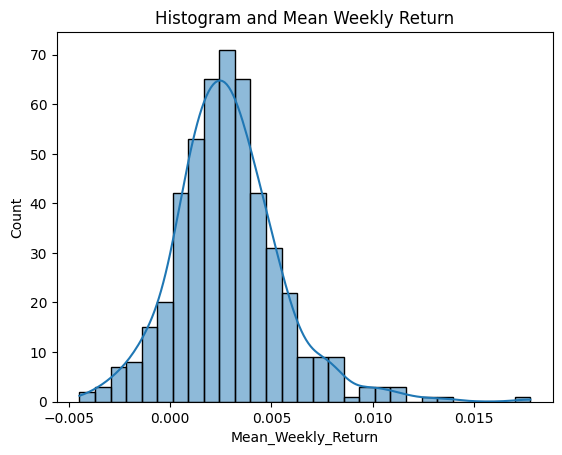

In [ ]:
# Cell 3
fig, ax = plt.subplots()
sns.histplot(data=data, x='Mean_Weekly_Return', kde=True)
ax.set_title('Histogram and Mean Weekly Return')
plt.show()

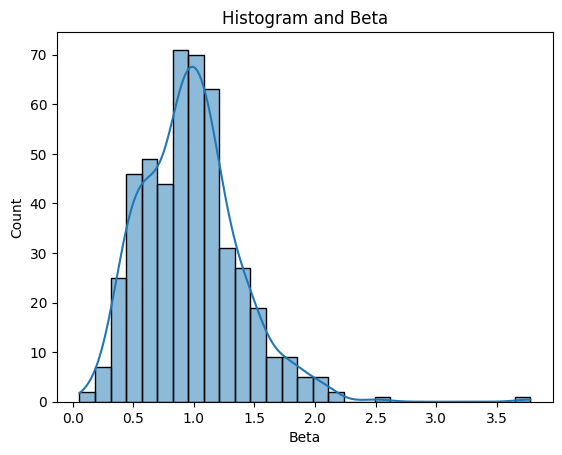

In [ ]:
# Cell 4
fig, ax = plt.subplots()
sns.histplot(data=data, x='Beta', kde=True)
ax.set_title('Histogram and Beta')
plt.show()

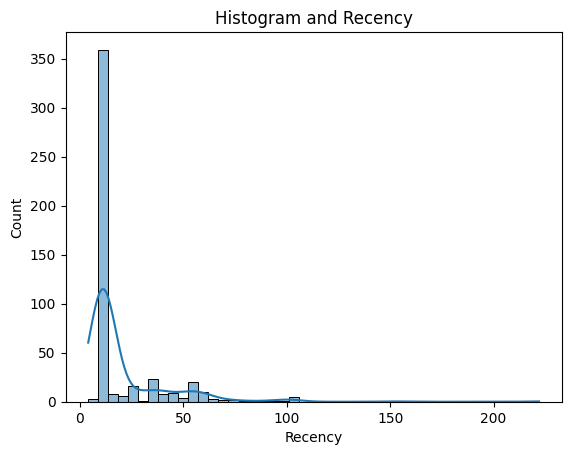

In [ ]:
# Cell 5
fig, ax = plt.subplots()
sns.histplot(data=data, x='Recency', kde=True)
ax.set_title('Histogram and Recency')
plt.show()

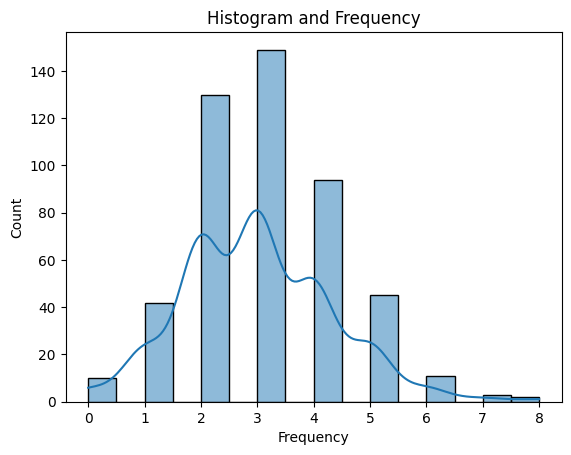

In [ ]:
# Cell 6
fig, ax = plt.subplots()
sns.histplot(data=data, x='Frequency', kde=True)
ax.set_title('Histogram and Frequency')
plt.show()

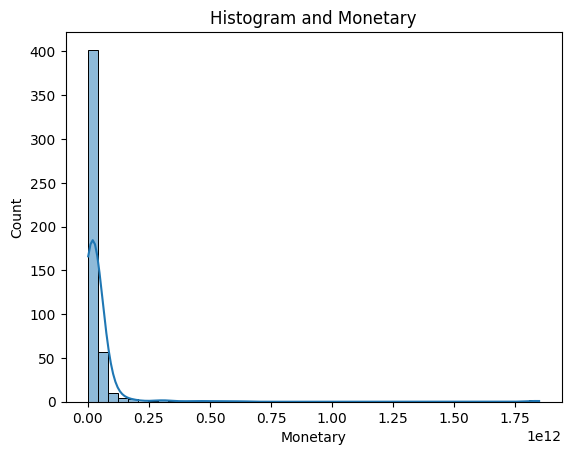

In [ ]:
# Cell 7
fig, ax = plt.subplots()
sns.histplot(data=data, x='Monetary', kde=True)
ax.set_title('Histogram and Monetary')
plt.show()

In [ ]:
# Cell 8
# Risk and return matrix: put both features on comparable scales
X_risk = data[risk_features].copy()
X_risk_scaled = StandardScaler().fit_transform(X_risk)

# Trading activity matrix: reduce the influence of very large traded values, then standardise
X_rfm = data[rfm_features].copy()
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
X_rfm_scaled = StandardScaler().fit_transform(X_rfm)

# Check: each standardised feature has mean 0 and standard deviation 1
print('Risk and return:', X_risk_scaled.mean(axis=0).round(2), X_risk_scaled.std(axis=0).round(2))
print('Trading activity:', X_rfm_scaled.mean(axis=0).round(2), X_rfm_scaled.std(axis=0).round(2))

Risk and return: [ 0. -0.] [1. 1.]
Trading activity: [-0. -0. -0.] [1. 1. 1.]


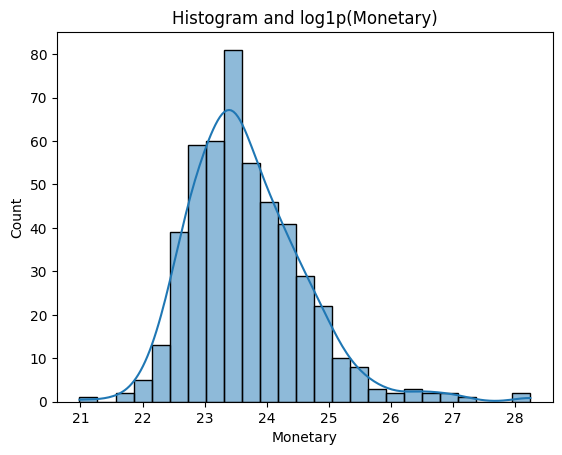

In [ ]:
# Cell 9
fig, ax = plt.subplots()
sns.histplot(data=X_rfm, x='Monetary', kde=True)
ax.set_title('Histogram and log1p(Monetary)')
plt.show()

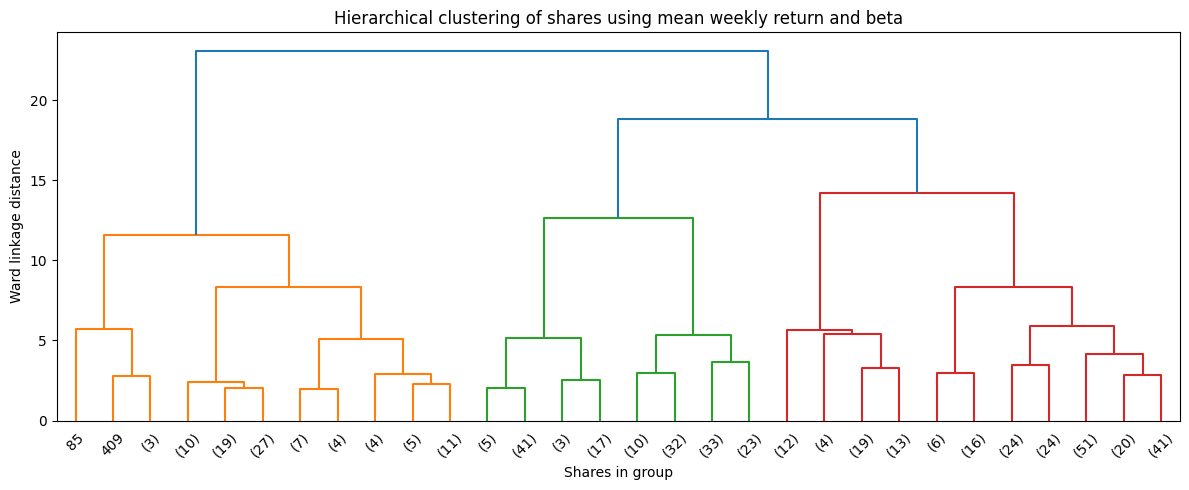

In [ ]:
# Cell 10
# Ward linkage groups shares using Euclidean distance
hierarchy_risk = linkage(X_risk_scaled, method="ward")

# Show only the last 30 merges; numbers in brackets are the shares in each group
plt.figure(figsize=(12, 5))
dendrogram(
    hierarchy_risk,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45
)
plt.title("Hierarchical clustering of shares using mean weekly return and beta")
plt.xlabel("Shares in group")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("dendrogram_risk_return.png", dpi=150)
plt.show()

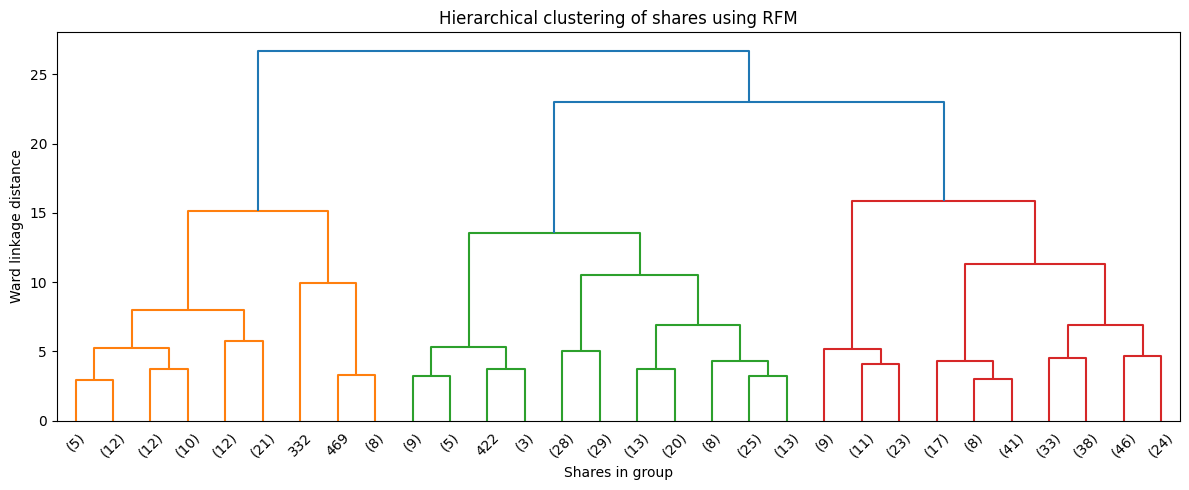

In [ ]:
# Cell 11
# Ward linkage groups shares using Euclidean distance
hierarchy_rfm = linkage(X_rfm_scaled, method="ward")

# Show only the last 30 merges; numbers in brackets are the shares in each group
plt.figure(figsize=(12, 5))
dendrogram(
    hierarchy_rfm,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45
)
plt.title("Hierarchical clustering of shares using RFM")
plt.xlabel("Shares in group")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("dendrogram_rfm.png", dpi=150)
plt.show()

In [ ]:
# Cell 12
# Compare cluster counts 2 to 8: silhouette score and cluster sizes
trial = data.copy()
results = []

for k in range(2, 9):
    trial["Cluster"] = cut_tree(hierarchy_risk, n_clusters=k).ravel() + 1
    results.append({
        "Matrix": "Risk and return",
        "k": k,
        "Silhouette": round(silhouette_score(X_risk_scaled, trial["Cluster"]), 3),
        "Cluster sizes": trial.groupby("Cluster")["Share"].count().tolist()
    })

    trial["Cluster"] = cut_tree(hierarchy_rfm, n_clusters=k).ravel() + 1
    results.append({
        "Matrix": "RFM",
        "k": k,
        "Silhouette": round(silhouette_score(X_rfm_scaled, trial["Cluster"]), 3),
        "Cluster sizes": trial.groupby("Cluster")["Share"].count().tolist()
    })

ward_comparison = pd.DataFrame(results, columns=["Matrix", "k", "Silhouette", "Cluster sizes"])
ward_comparison

,Matrix,k,Silhouette,Cluster sizes
0,Risk and return,2,0.339,"[394, 92]"
1,RFM,2,0.368,"[404, 82]"
2,Risk and return,3,0.274,"[230, 164, 92]"
3,RFM,3,0.304,"[154, 250, 82]"
4,Risk and return,4,0.282,"[182, 164, 48, 92]"
5,RFM,4,0.289,"[154, 207, 82, 43]"
6,Risk and return,5,0.304,"[182, 66, 98, 48, 92]"
7,RFM,5,0.305,"[154, 207, 72, 43, 10]"
8,Risk and return,6,0.320,"[182, 66, 98, 48, 87, 5]"
9,RFM,6,0.314,"[136, 207, 18, 72, 43, 10]"


In [ ]:
# Cell 13
# Cluster averages in original units for each cluster count
trial = data.copy()

for k in range(2, 9):
    trial["Cluster"] = cut_tree(hierarchy_risk, n_clusters=k).ravel() + 1
    print('Ward, risk and return, k =', k)
    print(trial.groupby("Cluster")[risk_features].mean().round(4))
    print()

for k in range(2, 9):
    trial["Cluster"] = cut_tree(hierarchy_rfm, n_clusters=k).ravel() + 1
    print('Ward, RFM, k =', k)
    print(trial.groupby("Cluster")[rfm_features].mean().round(2))
    print()

Ward, risk and return, k = 2
         Mean_Weekly_Return    Beta
Cluster                            
1                    0.0020  0.8979
2                    0.0063  1.2981

Ward, risk and return, k = 3
         Mean_Weekly_Return    Beta
Cluster                            
1                    0.0015  1.1096
2                    0.0029  0.6012
3                    0.0063  1.2981

Ward, risk and return, k = 4
         Mean_Weekly_Return    Beta
Cluster                            
1                    0.0013  0.9728
2                    0.0029  0.6012
3                    0.0020  1.6280
4                    0.0063  1.2981

Ward, risk and return, k = 5
         Mean_Weekly_Return    Beta
Cluster                            
1                    0.0013  0.9728
2                    0.0009  0.4390
3                    0.0042  0.7104
4                    0.0020  1.6280
5                    0.0063  1.2981

Ward, risk and return, k = 6
         Mean_Weekly_Return    Beta
Cluster                

In [ ]:
# Cell 14
# Compare k = 2 to 8: inertia, silhouette score and cluster sizes
# random_state fixes the seed; n_init=10 runs ten initialisations and keeps the best
trial = data.copy()
results = []
sse_risk = {}
sse_rfm = {}

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_risk_scaled)
    sse_risk[k] = kmeans.inertia_
    trial["Cluster"] = kmeans.labels_
    results.append({
        "Matrix": "Risk and return",
        "k": k,
        "Inertia": round(kmeans.inertia_, 2),
        "Silhouette": round(silhouette_score(X_risk_scaled, kmeans.labels_), 3),
        "Cluster sizes": trial.groupby("Cluster")["Share"].count().tolist()
    })

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_rfm_scaled)
    sse_rfm[k] = kmeans.inertia_
    trial["Cluster"] = kmeans.labels_
    results.append({
        "Matrix": "RFM",
        "k": k,
        "Inertia": round(kmeans.inertia_, 2),
        "Silhouette": round(silhouette_score(X_rfm_scaled, kmeans.labels_), 3),
        "Cluster sizes": trial.groupby("Cluster")["Share"].count().tolist()
    })

kmeans_comparison = pd.DataFrame(results, columns=["Matrix", "k", "Inertia", "Silhouette", "Cluster sizes"])
kmeans_comparison

,Matrix,k,Inertia,Silhouette,Cluster sizes
0,Risk and return,2,621.63,0.387,"[143, 343]"
1,RFM,2,1066.83,0.423,"[418, 68]"
2,Risk and return,3,461.18,0.329,"[202, 120, 164]"
3,RFM,3,796.67,0.325,"[272, 63, 151]"
4,Risk and return,4,371.58,0.327,"[132, 154, 40, 160]"
5,RFM,4,609.83,0.341,"[122, 92, 61, 211]"
6,Risk and return,5,309.61,0.341,"[112, 166, 131, 27, 50]"
7,RFM,5,514.71,0.358,"[68, 122, 87, 11, 198]"
8,Risk and return,6,265.71,0.326,"[115, 20, 85, 134, 56, 76]"
9,RFM,6,437.42,0.346,"[104, 120, 141, 69, 11, 41]"


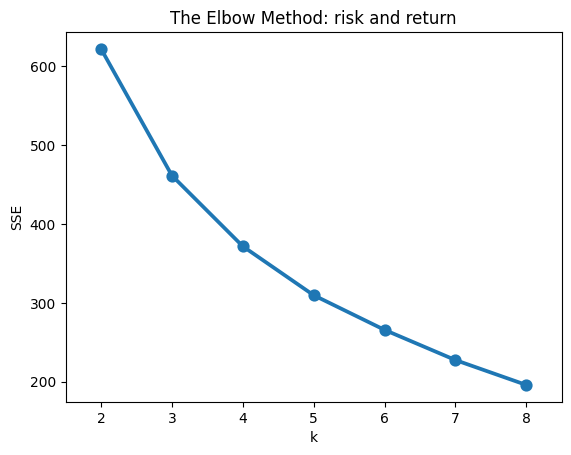

In [ ]:
# Cell 15
plt.title('The Elbow Method: risk and return')
plt.xlabel('k')
plt.ylabel('SSE')
sns.pointplot(x=list(sse_risk.keys()), y=list(sse_risk.values()))
plt.show()

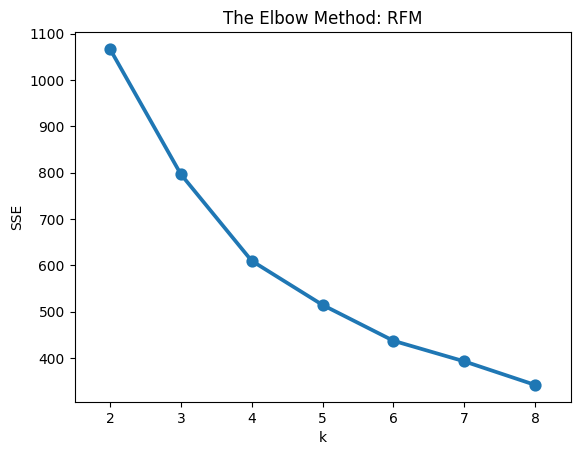

In [ ]:
# Cell 16
plt.title('The Elbow Method: RFM')
plt.xlabel('k')
plt.ylabel('SSE')
sns.pointplot(x=list(sse_rfm.keys()), y=list(sse_rfm.values()))
plt.show()

In [ ]:
# Cell 17
# Selected cluster counts (change these after reviewing 2.2 and 2.3)
k_ward_risk = 3
k_ward_rfm = 3
k_kmeans_risk = 3
k_kmeans_rfm = 3

# Final four baseline solutions
data["Ward_Risk"] = cut_tree(hierarchy_risk, n_clusters=k_ward_risk).ravel() + 1
data["Ward_RFM"] = cut_tree(hierarchy_rfm, n_clusters=k_ward_rfm).ravel() + 1

model = KMeans(n_clusters=k_kmeans_risk, random_state=42, n_init=10)
model.fit(X_risk_scaled)
data["KMeans_Risk"] = model.labels_ + 1

model = KMeans(n_clusters=k_kmeans_rfm, random_state=42, n_init=10)
model.fit(X_rfm_scaled)
data["KMeans_RFM"] = model.labels_ + 1

data.to_csv("cluster_assignments.csv", index=False)
data[["Share", "Ward_Risk", "KMeans_Risk", "Ward_RFM", "KMeans_RFM"]].head()

,Share,Ward_Risk,KMeans_Risk,Ward_RFM,KMeans_RFM
0,MMM,1,3,1,1
1,AOS,1,3,2,1
2,ABT,2,1,1,3
3,ABBV,2,1,1,3
4,ACN,1,3,1,3


In [ ]:
# Cell 18
# Risk and return cluster profiles in original units
for solution in ["Ward_Risk", "KMeans_Risk"]:
    print(solution)
    print(data.groupby(solution).agg({
        'Mean_Weekly_Return': 'mean',
        'Beta': ['mean', 'count']}).round(4))
    print()

Ward_Risk
          Mean_Weekly_Return    Beta      
                        mean    mean count
Ward_Risk                                 
1                     0.0015  1.1096   230
2                     0.0029  0.6012   164
3                     0.0063  1.2981    92

KMeans_Risk
            Mean_Weekly_Return    Beta      
                          mean    mean count
KMeans_Risk                                 
1                       0.0026  0.6308   202
2                       0.0059  1.3279   120
3                       0.0009  1.1368   164



In [ ]:
# Cell 19
# RFM cluster profiles in original units
for solution in ["Ward_RFM", "KMeans_RFM"]:
    print(solution)
    print(data.groupby(solution).agg({
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': ['mean', 'count']}).round(2))
    print()

Ward_RFM
         Recency Frequency      Monetary      
            mean      mean          mean count
Ward_RFM                                      
1          13.68      2.86  8.014525e+10   154
2          12.12      3.36  1.176413e+10   250
3           58.3      2.10  4.715898e+10    82

KMeans_RFM
           Recency Frequency      Monetary      
              mean      mean          mean count
KMeans_RFM                                      
1            13.48      3.35  1.205855e+10   272
2            65.06      1.68  5.508714e+10    63
3            14.25      2.89  8.211935e+10   151



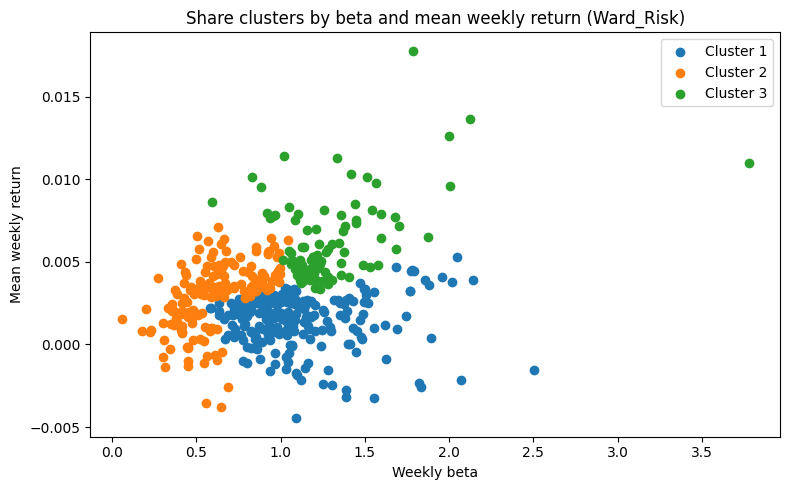

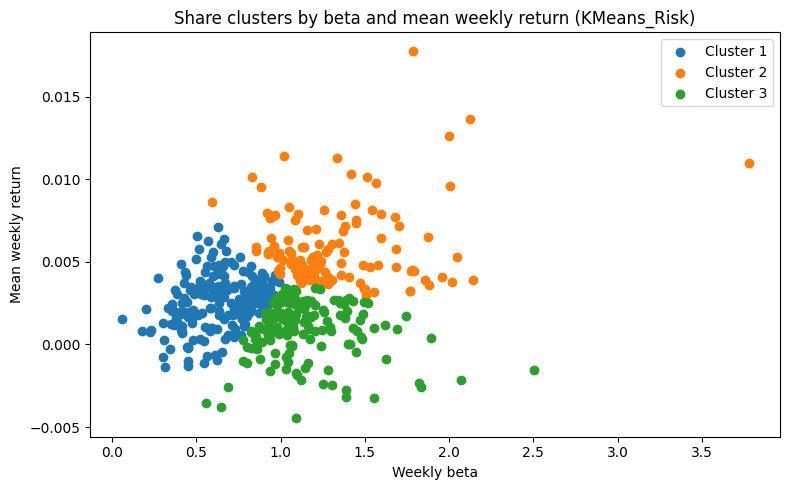

In [ ]:
# Cell 20
# Risk and return clusters plotted in original units (both features are shown, so no reduction is needed)
for solution in ["Ward_Risk", "KMeans_Risk"]:
    plt.figure(figsize=(8, 5))

    for cluster, group in data.groupby(solution):
        plt.scatter(group["Beta"], group["Mean_Weekly_Return"], label=f"Cluster {cluster}")

    plt.xlabel("Weekly beta")
    plt.ylabel("Mean weekly return")
    plt.title("Share clusters by beta and mean weekly return (" + solution + ")")
    plt.legend()
    plt.tight_layout()
    plt.savefig("scatter_" + solution + ".png", dpi=150)
    plt.show()

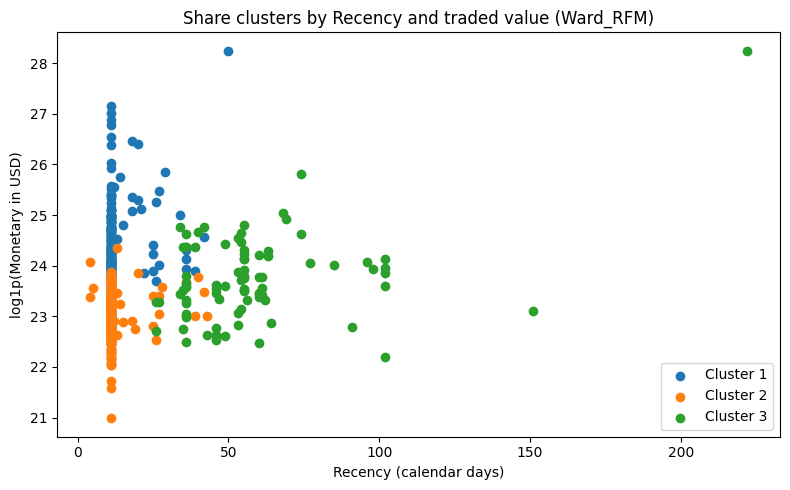

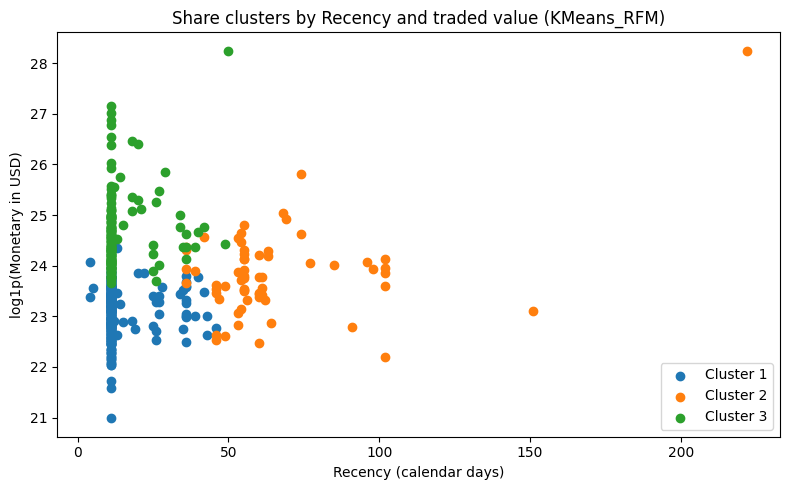

In [ ]:
# Cell 21
# RFM clusters: the model uses R, F and M; the plot shows Recency and log1p(Monetary)
for solution in ["Ward_RFM", "KMeans_RFM"]:
    plt.figure(figsize=(8, 5))

    for cluster, group in data.groupby(solution):
        plt.scatter(group["Recency"], np.log1p(group["Monetary"]), label=f"Cluster {cluster}")

    plt.xlabel("Recency (calendar days)")
    plt.ylabel("log1p(Monetary in USD)")
    plt.title("Share clusters by Recency and traded value (" + solution + ")")
    plt.legend()
    plt.tight_layout()
    plt.savefig("scatter_" + solution + ".png", dpi=150)
    plt.show()

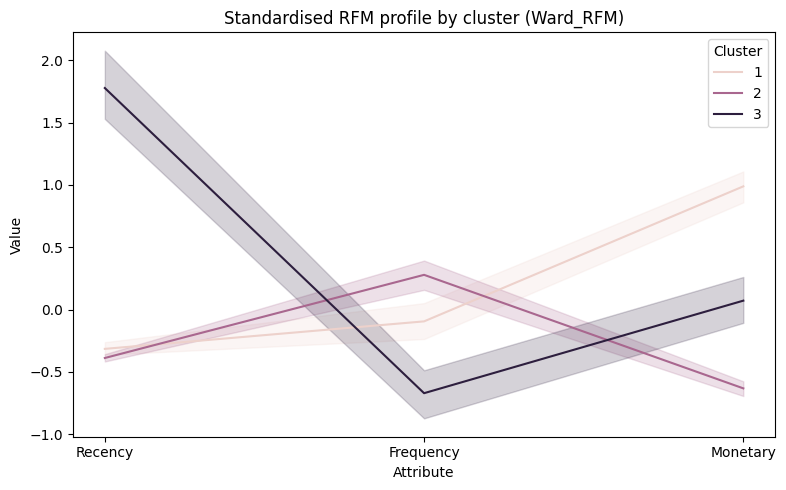

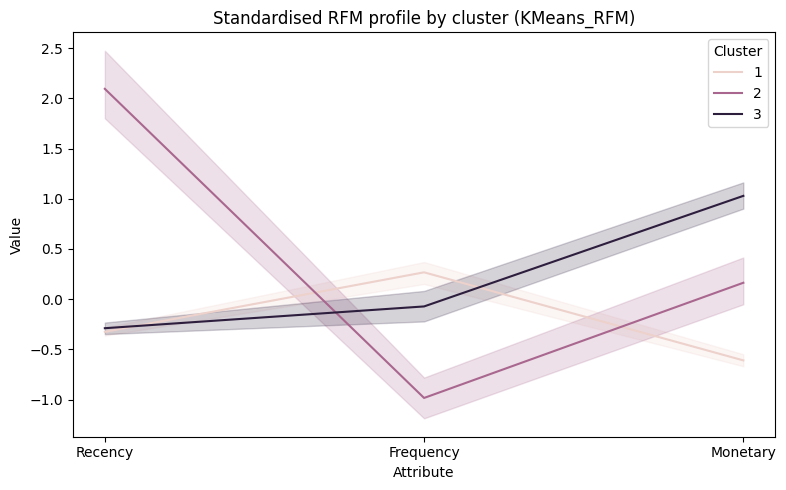

In [ ]:
# Cell 22
# Snake plot: all three standardised RFM features by cluster (Week 2 method)
for solution in ["Ward_RFM", "KMeans_RFM"]:
    df_normalized = pd.DataFrame(X_rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
    df_normalized['ID'] = data["Share"].values
    df_normalized['Cluster'] = data[solution].values

    df_nor_melt = pd.melt(df_normalized.reset_index(),
                          id_vars=['ID', 'Cluster'],
                          value_vars=['Recency', 'Frequency', 'Monetary'],
                          var_name='Attribute',
                          value_name='Value')

    plt.figure(figsize=(8, 5))
    sns.lineplot(x='Attribute', y='Value', hue='Cluster', data=df_nor_melt)
    plt.title("Standardised RFM profile by cluster (" + solution + ")")
    plt.tight_layout()
    plt.savefig("snake_" + solution + ".png", dpi=150)
    plt.show()

In [ ]:
# Cell 23
# Compare Ward and K-means on the same shares: number of shares in each pair of clusters
print(data.groupby(["Ward_Risk", "KMeans_Risk"])["Share"].count())
print('Adjusted Rand index (Ward vs K-means, risk and return):',
      round(adjusted_rand_score(data["Ward_Risk"], data["KMeans_Risk"]), 3))
print()
print(data.groupby(["Ward_RFM", "KMeans_RFM"])["Share"].count())
print('Adjusted Rand index (Ward vs K-means, RFM):',
      round(adjusted_rand_score(data["Ward_RFM"], data["KMeans_RFM"]), 3))

Ward_Risk  KMeans_Risk
1          1               54
           2               17
           3              159
2          1              148
           2               13
           3                3
3          2               90
           3                2
Name: Share, dtype: int64
Adjusted Rand index (Ward vs K-means, risk and return): 0.512

Ward_RFM  KMeans_RFM
1         1               6
          2               5
          3             143
2         1             250
3         1              16
          2              58
          3               8
Name: Share, dtype: int64
Adjusted Rand index (Ward vs K-means, RFM): 0.822


In [ ]:
# Cell 24
features = data[["Recency", "Frequency", "Monetary"]].copy()
features["LogMonetary"] = np.log1p(features["Monetary"])

print("Correlations among the clustering inputs:")
rfm_correlations = features[["Recency", "Frequency", "LogMonetary"]].corr().round(2)
rfm_correlations.to_csv("rfm_correlations.csv")
rfm_correlations

Correlations among the clustering inputs:


,Recency,Frequency,LogMonetary
Recency,1.00,-0.35,0.15
Frequency,-0.35,1.00,0.01
LogMonetary,0.15,0.01,1.00


In [ ]:
# Cell 25
# Repeat the selected Ward RFM solution with Recency and Frequency only, on the same shares and cluster count
X_rf = data[["Recency", "Frequency"]].copy()
X_rf_scaled = StandardScaler().fit_transform(X_rf)

hierarchy_rf = linkage(X_rf_scaled, method="ward")
data["Ward_RF"] = cut_tree(hierarchy_rf, n_clusters=k_ward_rfm).ravel() + 1

print('Adjusted Rand index (Ward RFM vs Ward RF):',
      round(adjusted_rand_score(data["Ward_RFM"], data["Ward_RF"]), 3))
print()
print(data.groupby(["Ward_RFM", "Ward_RF"])["Share"].count())
data.to_csv("cluster_assignments.csv", index=False)

Adjusted Rand index (Ward RFM vs Ward RF): 0.291

Ward_RFM  Ward_RF
1         1           86
          2           59
          3            9
2         1          183
          2           66
          3            1
3         1            3
          3           79
Name: Share, dtype: int64


In [ ]:
# Cell 26
# Traded value (Monetary) profiles with and without Monetary in the clustering
print('With Monetary (Ward_RFM):')
print(data.groupby("Ward_RFM").agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']}).round(2))
print()
print('Without Monetary (Ward_RF):')
print(data.groupby("Ward_RF").agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']}).round(2))

With Monetary (Ward_RFM):
         Recency Frequency      Monetary      
            mean      mean          mean count
Ward_RFM                                      
1          13.68      2.86  8.014525e+10   154
2          12.12      3.36  1.176413e+10   250
3           58.3      2.10  4.715898e+10    82

Without Monetary (Ward_RF):
        Recency Frequency      Monetary      
           mean      mean          mean count
Ward_RF                                      
1         12.88      3.86  3.940097e+10   272
2         11.04      1.80  3.433790e+10   125
3         56.56      2.01  4.652963e+10    89


In [ ]:
# Task 3
# Cell 1
# Calculation log: sources, windows, observation date, settings and cluster counts for this run
run_log = pd.Series({
    "Ticker source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
    "Price source": "yfinance",
    "Retrieval date": retrieval_date,
    "Study period": start + " to " + end + " (end exclusive)",
    "Observation date": str(observation_date.date()),
    "Weekly returns": "W-FRI, last price in week",
    "Weeks of returns": len(weekly_returns),
    "RFM window": "60 trading sessions",
    "High-volume rule": "volume > 2 x mean of preceding 20 sessions",
    "Shares in common set": len(data),
    "k Ward risk and return": k_ward_risk,
    "k Ward RFM": k_ward_rfm,
    "k K-means risk and return": k_kmeans_risk,
    "k K-means RFM": k_kmeans_rfm,
    "K-means random_state": 42,
    "K-means n_init": 10
}, name="Value")
run_log.to_csv("run_log.csv")
run_log

,Value
Ticker source,https://en.wikipedia.org/wiki/List_of_S%26P_50...
Price source,yfinance
Retrieval date,2026-11-23
Study period,2021-01-01 to 2025-01-01 (end exclusive)
Observation date,2024-12-31
Weekly returns,"W-FRI, last price in week"
Weeks of returns,208
RFM window,60 trading sessions
High-volume rule,volume > 2 x mean of preceding 20 sessions
Shares in common set,486


In [ ]:
# Cell 2
# Profiles of every cluster solution on all five features in original units
for solution in ["Ward_Risk", "KMeans_Risk", "Ward_RFM", "KMeans_RFM"]:
    print(solution)
    print(data.groupby(solution).agg({
        'Mean_Weekly_Return': 'mean',
        'Beta': 'mean',
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': ['mean', 'count']}).round(4))
    print()

Ward_Risk
          Mean_Weekly_Return    Beta  Recency Frequency      Monetary      
                        mean    mean     mean      mean          mean count
Ward_Risk                                                                  
1                     0.0015  1.1096  18.9304    3.0565  3.380100e+10   230
2                     0.0029  0.6012  20.6463    2.7805  2.517294e+10   164
3                     0.0063  1.2981  23.6739    3.1957  7.878092e+10    92

KMeans_Risk
            Mean_Weekly_Return    Beta  Recency Frequency      Monetary      
                          mean    mean     mean      mean          mean count
KMeans_Risk                                                                  
1                       0.0026  0.6308  19.9307    2.9109  2.343970e+10   202
2                       0.0059  1.3279  23.5833    3.1083  8.643910e+10   120
3                       0.0009  1.1368  18.6707    3.0000  2.465199e+10   164

Ward_RFM
         Mean_Weekly_Return    Beta  Recenc

In [ ]:
# Cell 3
# Compare risk and return clusters with RFM clusters on the same shares
print(data.groupby(["Ward_Risk", "Ward_RFM"])["Share"].count())
print('Adjusted Rand index (Ward risk and return vs Ward RFM):',
      round(adjusted_rand_score(data["Ward_Risk"], data["Ward_RFM"]), 3))
print()
print(data.groupby(["KMeans_Risk", "KMeans_RFM"])["Share"].count())
print('Adjusted Rand index (K-means risk and return vs K-means RFM):',
      round(adjusted_rand_score(data["KMeans_Risk"], data["KMeans_RFM"]), 3))

Ward_Risk  Ward_RFM
1          1            59
           2           134
           3            37
2          1            58
           2            80
           3            26
3          1            37
           2            36
           3            19
Name: Share, dtype: int64
Adjusted Rand index (Ward risk and return vs Ward RFM): 0.024

KMeans_Risk  KMeans_RFM
1            1             118
             2              25
             3              59
2            1              51
             2              18
             3              51
3            1             103
             2              20
             3              41
Name: Share, dtype: int64
Adjusted Rand index (K-means risk and return vs K-means RFM): 0.019


In [ ]:
# Cell 4
# Sector composition: number of shares from each GICS Sector in each cluster
for solution in ["Ward_Risk", "KMeans_Risk", "Ward_RFM", "KMeans_RFM"]:
    print(solution)
    print(data.groupby([solution, "GICS Sector"])["Share"].count())
    print()

Ward_Risk
Ward_Risk  GICS Sector           
1          Communication Services     7
           Consumer Discretionary    27
           Consumer Staples           5
           Financials                31
           Health Care               29
           Industrials               44
           Information Technology    43
           Materials                 16
           Real Estate               23
           Utilities                  5
2          Communication Services     8
           Consumer Discretionary     9
           Consumer Staples          27
           Energy                    16
           Financials                30
           Health Care               27
           Industrials               13
           Information Technology     2
           Materials                  4
           Real Estate                4
           Utilities                 24
3          Communication Services     5
           Consumer Discretionary    11
           Energy                   

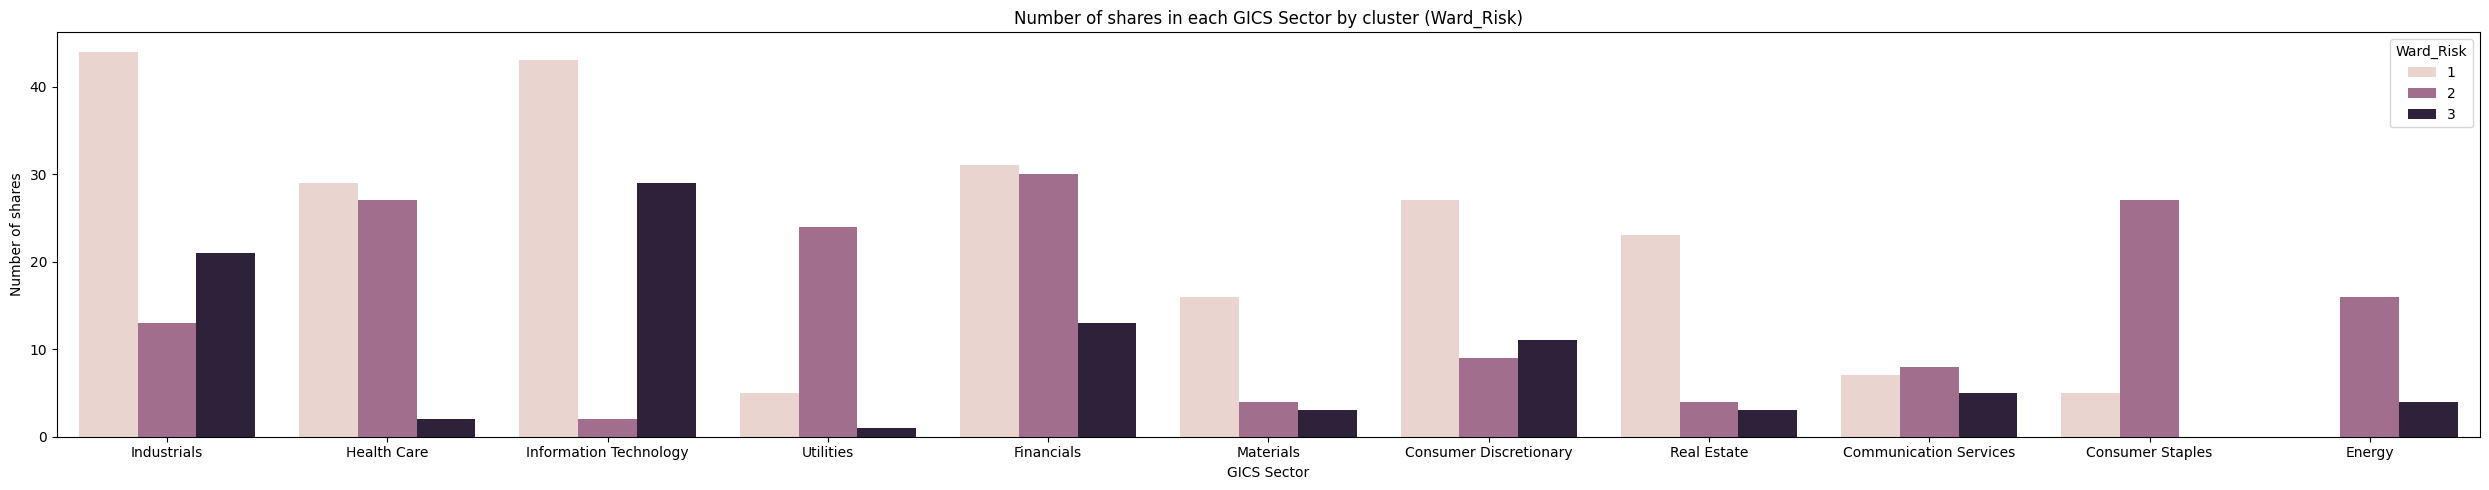

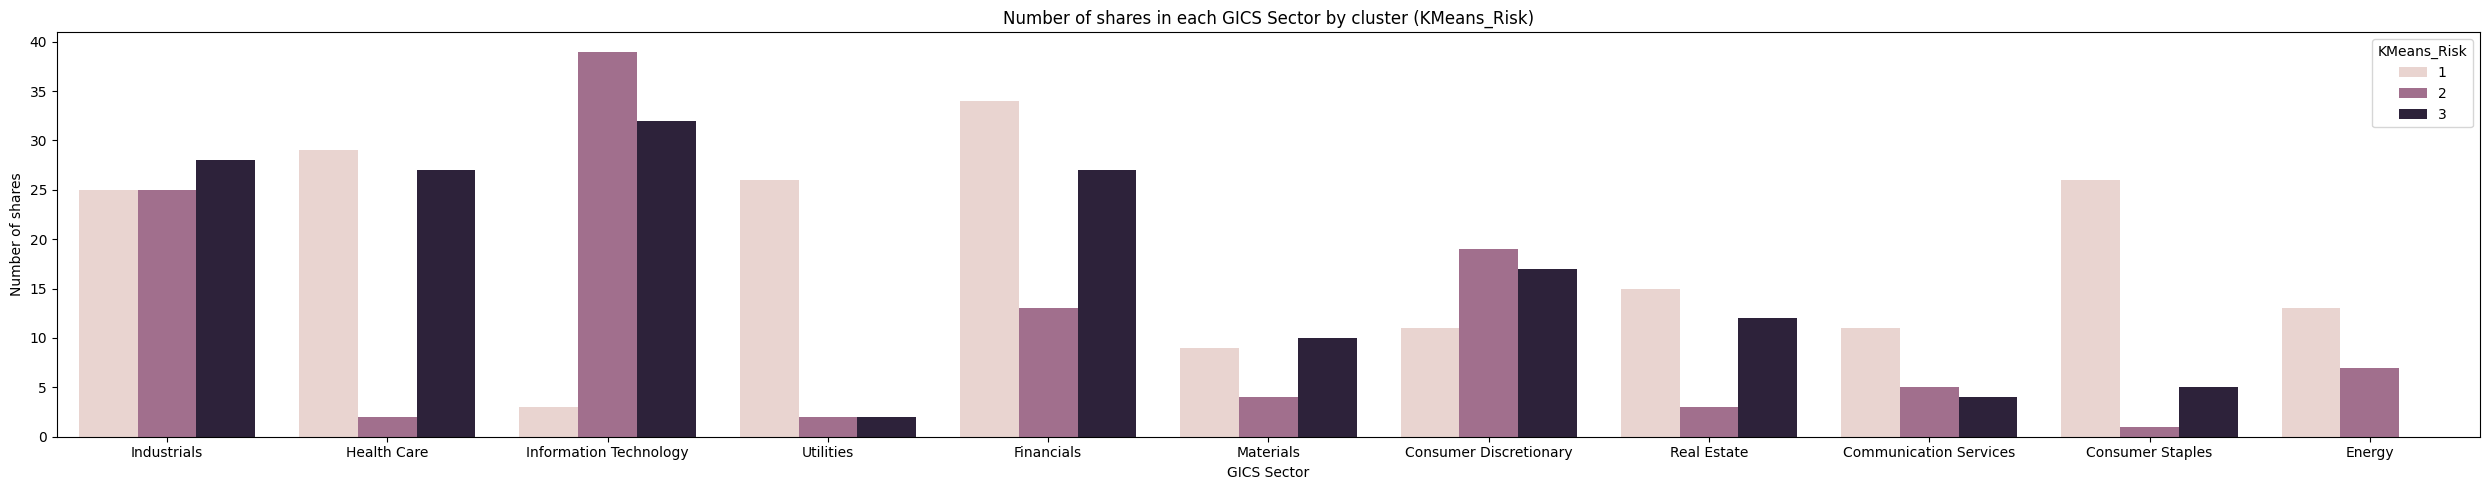

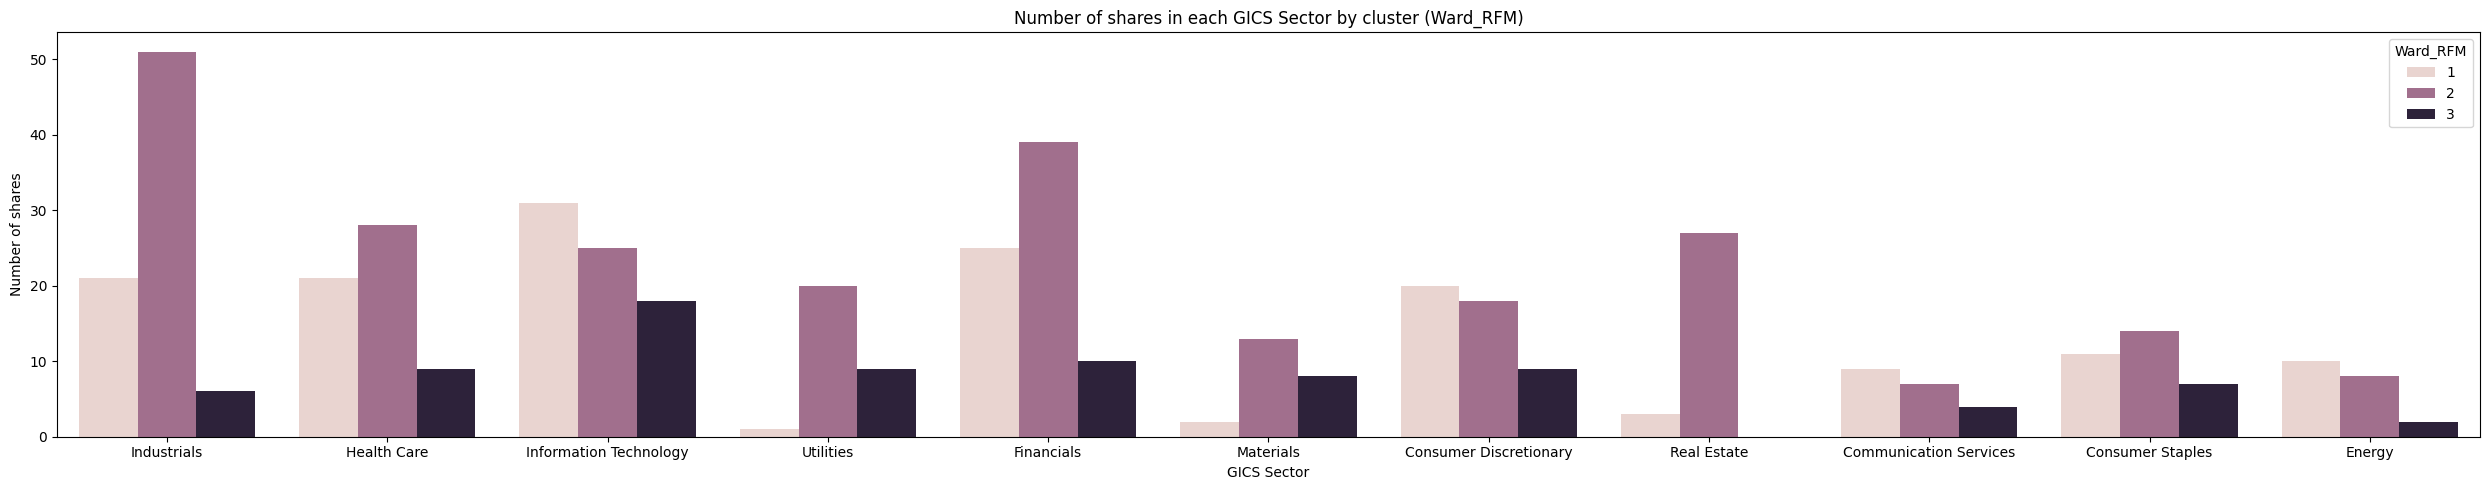

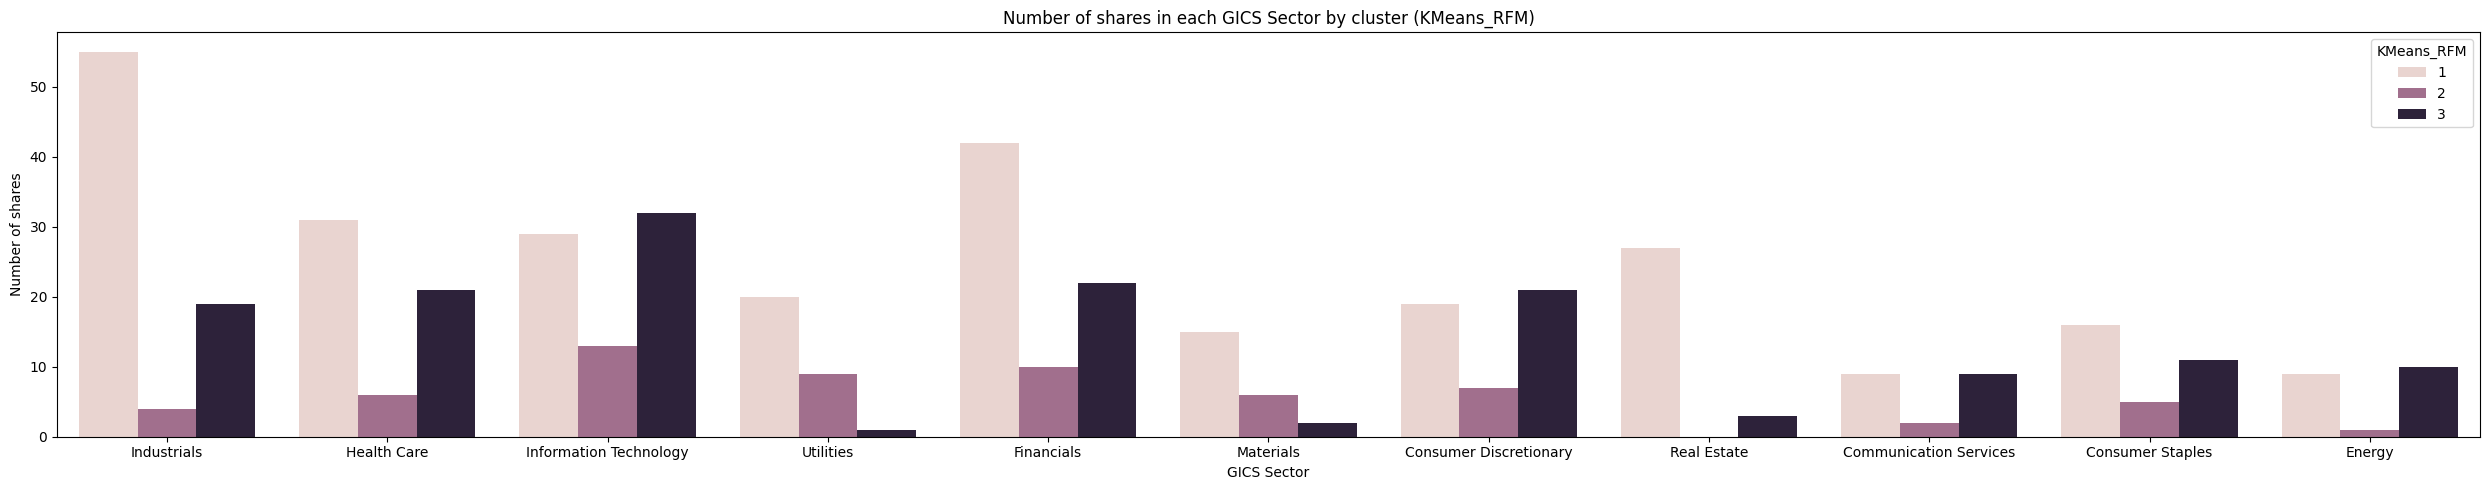

In [ ]:
# Cell 5
# Sector composition charts
for solution in ["Ward_Risk", "KMeans_Risk", "Ward_RFM", "KMeans_RFM"]:
    f, ax = plt.subplots(figsize=(25, 5))
    ax = sns.countplot(x="GICS Sector", hue=solution, data=data)
    ax.set_title("Number of shares in each GICS Sector by cluster (" + solution + ")")
    ax.set_xlabel("GICS Sector")
    ax.set_ylabel("Number of shares")
    plt.tight_layout()
    plt.savefig("sectors_" + solution + ".png", dpi=150)
    plt.show()

In [ ]:
# Cell 6
# Return dependencies: how many shares move with the market
print('Shares with positive beta:', int((data["Beta"] > 0).sum()), 'of', len(data))
print('Shares with beta above 1:', int((data["Beta"] > 1).sum()), 'of', len(data))

Shares with positive beta: 486 of 486
Shares with beta above 1: 216 of 486
